# 04 · Ответ на бизнес-вопрос

**Вопрос.** Школа тратит ≈ €150k в год на рекламу и получает ≈ 20k лидов, но платят только 4.2%.
**Где теряются продажи и какой самый дешёвый рычаг роста прибыли?**

Этот ноутбук ничего нового не «открывает»: он собирает выводы ноутбуков 01–03 в одну цепочку
«вопрос → доказательства → решение» и сравнивает рычаги в евро. Цифры берутся из данных и из
`reports/results_03.json` (его сохраняет ноутбук 03), а не переписываются вручную.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # обратная совместимость типов pandas, на расчёты не влияет
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import cleaning as etl
import metrics as M
import viz
from viz import PRIMARY, ACCENT, MUTED, save, eur_axis

viz.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

data = etl.load_clean()
deals, calls, spend = data["Deals"], data["Calls"], data["Spend"]
d = M.add_contact_metrics(deals, calls)
R = json.loads((Path.cwd().parent / "reports" / "results_03.json").read_text(encoding="utf-8"))
fun = M.funnel(d, calls)

## 1. Короткий ответ

1. **Продажи теряются на первом контакте и квалификации, а не на цене.** 31% лидов ни разу не поговорили с
   менеджером, до консультации доходят только 17%. После консультации воронка работает: 72% выставленных счетов оплачиваются.
2. **Причина — отдел продаж не успел за ростом трафика.** Лидов стало в 3 раза больше, доля ответов быстрее
   15 минут упала с 21% до 3%, а конверсия упала *внутри* каналов, а не из-за смены их структуры.
3. **Точка роста — C1, и для неё есть пять гипотез**, по одной на каждый шаг воронки (ноутбук 03, раздел 4):
   скорость ответа, повторные касания, скрипт разговора, вечерняя группа, напоминания об оплате. Все не требуют
   рекламного бюджета. **Первой проверяем скорость ответа (H1)** — единственную, которую A/B-тест различит за 14 дней:
   при подтверждении это +€150–375k маржи в год. Самый большой потенциал у скрипта разговора (H3, ≈ +€511k), он
   идёт следующим тестом. Параллельно без всякого теста можно сэкономить ≈ €33k, отключив кампанию Performance Max.

## 2. Цепочка доказательств

In [2]:
lost = d[d["stage"].eq("Lost")]
no_answer = lost["lost_reason"].isin(["Doesn't Answer", "Stopped Answering"]).mean()
never_talked = 1 - fun.loc["Разговор ≥ 30 с", "% от лидов"]
to_consult = fun.loc["Консультация (указан продукт)", "% от лидов"]
inv_paid = fun.loc["Студент", "конверсия шага"]
evidence = pd.DataFrame([
    ("Где теряются продажи?", f"{never_talked:.0%} лидов без разговора; до консультации доходят {to_consult:.0%}; "
     f"оплачивается {inv_paid:.0%} счетов", "02 · 1.3 воронка"),
    ("Почему?", f"{no_answer:.0%} проигранных — «не отвечает / перестал отвечать»", "02 · 1.2 причины отказа"),
    ("Это из-за трафика?", "нет: падение C1 и доли A+B — внутри каналов (структура < 0.2 п.п.)", "02 · 2.3 shift-share"),
    ("Что изменилось?", "доля ответов < 15 мин: 21% → 3%, медианный SLA 1 ч → 5–7 ч", "02 · 2.3"),
    ("Скорость важна?", f"дозвон 77% vs 59%; с учётом источника, времени, месяца и менеджера +{R['reach_gap_adjusted_pp']:.0f} п.п.",
     "02 · 7, 03 · 4 регрессия"),
    ("Какой рычаг сильнее?", f"+10% к C1 = +€{R['sensitivity_C1_plus10'] / 1e3:,.0f}k маржи без роста бюджета; −10% CPA = +€15k",
     "03 · 2 чувствительность"),
    ("Можно ли проверить за 14 дней?", f"да, если звонить {R['test_window']}: MDE +{R['test_mde_pp']:.1f} п.п. < эффекта "
     f"+{R['test_expected_pp']:.1f} п.п.; в будни 9–18 — нет (MDE +{R['office_hours_mde_pp']:.1f} > +{R['office_hours_expected_pp']:.1f})",
     "03 · 5 дизайн теста"),
], columns=["вопрос", "что показывают данные", "где"]).set_index("вопрос")
evidence

,что показывают данные,где
вопрос,,
Где теряются продажи?,31% лидов без разговора; до консультации доходят 17%; оплачивается 72% счетов,02 · 1.3 воронка
Почему?,40% проигранных — «не отвечает / перестал отвечать»,02 · 1.2 причины отказа
Это из-за трафика?,нет: падение C1 и доли A+B — внутри каналов (структура < 0.2 п.п.),02 · 2.3 shift-share
Что изменилось?,"доля ответов < 15 мин: 21% → 3%, медианный SLA 1 ч → 5–7 ч",02 · 2.3
Скорость важна?,"дозвон 77% vs 59%; с учётом источника, времени, месяца и менеджера +19 п.п.","02 · 7, 03 · 4 регрессия"
Какой рычаг сильнее?,+10% к C1 = +€334k маржи без роста бюджета; −10% CPA = +€15k,03 · 2 чувствительность
Можно ли проверить за 14 дней?,"да, если звонить ежедневно 8:00–23:00: MDE +9.4 п.п. < эффекта +12.2 п.п.; в будни 9–18 — нет (MDE +13.6 > +11.0)",03 · 5 дизайн теста


## 3. Сравнение рычагов в евро

| Рычаг | Как оцениваем ΔCM за год |
|---|---|
| Скорость первого ответа | сценарии ноутбука 03 (раздел 7): выполнение правила 80–100%, перенос разницы C1 50–100% |
| Отключить Performance Max | расход кампании минус выручка её студентов (их потеряем) |
| Срезать бюджет на 10% равномерно | для сравнения: экономия минус потерянная маржа (CPA постоянен) |

Вечерние группы и продуктовые гипотезы в евро не оцениваем: при 3–4 лидах с продуктом в день их эффект
нельзя надёжно измерить за 2 недели (ноутбук 03, раздел 6) — они идут в план как пилоты.

In [3]:
pm = "performancemax_eng_DE"
pm_spend = spend.loc[spend["campaign"].eq(pm), "spend"].sum()
pm_deals = d[d["campaign"].eq(pm)]
pm_dcm = pm_spend - pm_deals["revenue"].sum()

g_spend = spend.loc[spend["source"].eq("Google Ads"), "spend"].sum()
g_st = d.loc[d["source"].eq("Google Ads"), "is_student"].sum()
fb_cac = spend.loc[spend["source"].eq("Facebook Ads"), "spend"].sum() / d.loc[d["source"].eq("Facebook Ads"), "is_student"].sum()
print(f"Performance Max: €{pm_spend:,.0f} расходов, {len(pm_deals)} лидов, {pm_deals['is_student'].sum()} студент")
print(f"CAC Google Ads: с PMax €{g_spend / g_st:,.0f}, без PMax €{(g_spend - pm_spend) / (g_st - pm_deals['is_student'].sum()):,.0f} "
      f"(Facebook €{fb_cac:,.0f})")

cut10 = 0.10 * spend["spend"].sum() - 0.10 * (R["CM"] + spend["spend"].sum())   # −10% бюджета = −10% лидов
levers = pd.DataFrame({
    "ΔCM мин, €": [R["cm_uplift"]["conservative"], pm_dcm, cut10],
    "ΔCM макс, €": [R["cm_uplift"]["optimistic"], pm_dcm, cut10],
    "нужен рекламный бюджет": ["нет", "нет (экономия)", "нет"],
    "как проверить": ["A/B-тест 14 дней + C1 через 45 дней", "сразу, контроль заявок Google 2–4 недели", "—"],
}, index=["Ответ ≤ 15 мин, 8:00–23:00", "Отключить Performance Max", "Срезать весь бюджет на 10%"])
levers.style.format({"ΔCM мин, €": "€{:+,.0f}", "ΔCM макс, €": "€{:+,.0f}"})

Performance Max: €34,183 расходов, 241 лидов, 1 студент
CAC Google Ads: с PMax €344, без PMax €141 (Facebook €172)


,"ΔCM мин, €","ΔCM макс, €",нужен рекламный бюджет,как проверить
"Ответ ≤ 15 мин, 8:00–23:00","€+149,934","€+374,835",нет,A/B-тест 14 дней + C1 через 45 дней
Отключить Performance Max,"€+33,183","€+33,183",нет (экономия),"сразу, контроль заявок Google 2–4 недели"
Срезать весь бюджет на 10%,"€-319,483","€-319,483",нет,—


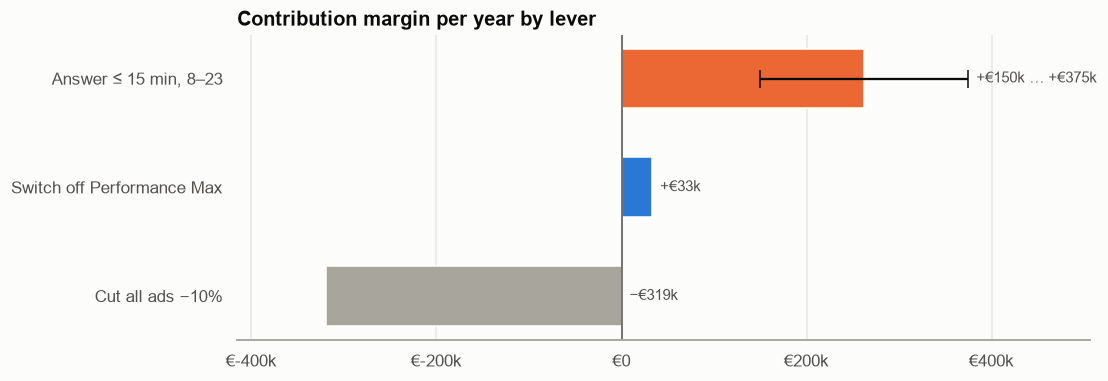

In [4]:
p = levers.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(p))
mid = (p["ΔCM мин, €"] + p["ΔCM макс, €"]) / 2
ax.barh(y, mid, color=[MUTED, PRIMARY, ACCENT], height=0.55)
rng = p["ΔCM макс, €"] > p["ΔCM мин, €"]
ax.errorbar(mid[rng], y[rng.values], xerr=(p["ΔCM макс, €"] - p["ΔCM мин, €"])[rng] / 2, fmt="none", ecolor=viz.TEXT, capsize=6, lw=1.5)
k = lambda v: f"{'+' if v >= 0 else '−'}€{abs(v) / 1e3:,.0f}k"
for yi, (lo, hi) in zip(y, zip(p["ΔCM мин, €"], p["ΔCM макс, €"])):
    label = k(lo) if lo == hi else f"{k(lo)} … {k(hi)}"
    ax.text(max(hi, 0), yi, "  " + label, va="center", fontsize=10, color=viz.TEXT_2)
ax.axvline(0, color=viz.TEXT_2, lw=1)
ax.set_yticks(y, ["Cut all ads −10%", "Switch off Performance Max", "Answer ≤ 15 min, 8–23"])
eur_axis(ax, "x"); ax.set_xlim(min(0, p["ΔCM мин, €"].min()) * 1.3, p["ΔCM макс, €"].max() * 1.35)
ax.set_title("Contribution margin per year by lever"); ax.grid(axis="y", visible=False)
save(fig, "04_levers"); plt.show()

**Чтение:** скорость ответа даёт на порядок больше остальных рычагов и не требует рекламного бюджета.
Нужны только смены менеджеров вечером и в выходные и автоматическое распределение лидов. Отсюда критерий решения:
**внедрение окупается, если дополнительные смены и автоматизация стоят меньше €150k в год** (консервативный сценарий).
Экономия на рекламе даёт мало: маркетинг уже дешёвый (CAC €179 при CLTV ≈ €4k), и равномерное сокращение бюджета
теряет больше маржи, чем экономит. Исключение — явно провальные кампании вроде Performance Max.

**Google Ads как канал не плохой.** Высокий CAC Google Ads (€344) почти целиком создаёт Performance Max.
Без этой кампании Google Ads дешевле Facebook, поэтому перераспределять весь бюджет из Google в Facebook не нужно.

## 4. План действий

| Когда | Действие | Метрика успеха |
|---|---|---|
| Неделя 1 | Отключить `performancemax_eng_DE`; настроить автоназначение лида и сообщение клиенту | расходы −€34k/год; число заявок из Google не упало |
| Неделя 1 | 3-дневный технический пилот маршрутизации со сменами 8:00–23:00 | ≥ 80% лидов получают звонок ≤ 15 мин |
| Недели 2–3 | A/B-тест «ответ ≤ 15 мин» (дизайн — ноутбук 03, раздел 5) | `reached_24h` +≥ 9.4 п.п., guardrails в норме |
| +45 дней | Проверка C1 по когортам теста; решение о внедрении на 100% | C1 группы B выше контроля |
| Месяцы 2–4 | H3: пилот скрипта «запись на консультацию в первом звонке» на 2–3 менеджерах, затем A/B (~87 дней) | доля консультаций после разговора, затем C1 |
| Параллельно | Пилоты H2 (повторные касания), H4 (вечерняя группа), H5 (напоминания об оплате) с замером до/после | шаг воронки каждой гипотезы |
| Постоянно | Обязательные поля CRM (продукт, тип оплаты, дата закрытия) и единая UTM-разметка | доля заполнения ≥ 95%; 100% кампаний сопоставлены со Spend |

## 5. Ограничения — что может изменить ответ

- **Наблюдательные данные.** Связь «скорость → дозвон» устойчива к контролю источника, времени, месяца и менеджера,
  но не доказывает причинность. Поэтому рекомендация — сначала тест, потом внедрение.
- **Перенос дозвона в C1** оценён по наблюдательной разнице (6.8% vs 2.3%), поэтому эффект дан диапазоном.
- **Себестоимости обучения нет в данных**: CM — маржа после маркетинга, это верхняя граница прибыли.
- **Свежие когорты не «дозрели»**: C1 за апрель–июнь 2024 занижена; вывод о падении опирается и на долю A+B, которая от этого не зависит.
- **Разметка кампаний**: только 30% названий кампаний из Deals есть в Spend, поэтому CAC по кампаниям — оценка.
- **Продукт известен у 17% лидов** — юнит-экономика по продуктам распределяет лиды и бюджет пропорционально (ноутбук 03).